# CMP629 — Mini-projeto MountainCar-v0
## Entrega final: código, resultados e análise

**Integrantes:**

Caetano gubert meneghetti

Fernando bosquetti tedesco

Gabriel de senne amorim

José antônio coutinho de moraes filho

**CMP629 — Aprendizado por Reforço · versão de 13/10/2026**

Este notebook reaproveita **108 execuções exploratórias e 60 treinamentos finais**. Executar todas as células apenas lê os dados preservados, calcula estatísticas e gráficos e mostra vídeos reais. **Nenhum treinamento ou nova avaliação de políticas é executado.** Os dados necessários à apresentação estão incorporados; não é necessário baixar o repositório.

**Resultado principal:** SARSA(λ) teve a maior média observada de sucesso greedy: 83,7% em 4×2 e 100% em 12×4. Q-learning atingiu 38,2% e 73,6%; Dyna-Q, 0% e 31,8%. Esses resultados valem para o protocolo estudado, sem superioridade universal.

**Origem:** notebook `MountainCar_CMP629_Colab(2).ipynb`, relatório anterior e repositório `antoniomoraes85/reinforcement-learning-projects`, commit `19dcf17bfa589bb3cb16da4bd9f1862c501fddbd`. O notebook-base específico do professor não foi fornecido entre os anexos; o notebook existente foi reorganizado conforme as seções 4.1–4.3 do enunciado. O notebook de Monte Carlo pertence a outro problema e não foi alterado.

**Roteiro:** 1. Modelagem; 2. Código dos agentes; 3. Protocolo; 4. Resultados e gráficos; 5. Custos; 6. Aliasing; 7. Vídeos; 8. Diário; 9. Conclusões e referências.

**Uso:** Python 3.10+, NumPy, pandas, SciPy, Matplotlib e IPython. O Colab normalmente já dispõe dessas bibliotecas. Gymnasium 1.2.1 só é necessário para executar as funções de interação com o ambiente, que não são chamadas nesta entrega.

In [1]:
RUN_TRAINING = False
RUN_EVALUATION = False
import io, json, gzip, hashlib, base64, zipfile, pathlib, sys, platform, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Image, Video, Markdown
OUT = pathlib.Path('cmp629_reproduzido')
OUT.mkdir(exist_ok=True)
LABELS = {'q_learning':'Q-learning', 'sarsa_lambda':'SARSA(λ)', 'dyna_q':'Dyna-Q'}
COLORS = {'q_learning':'#0072B2', 'sarsa_lambda':'#B75B27', 'dyna_q':'#52796F'}
LINES = {'q_learning':'-', 'sarsa_lambda':'--', 'dyna_q':':'}
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.titlesize':12,
 'axes.labelsize':11,'legend.fontsize':10,'xtick.labelsize':10,'ytick.labelsize':10,
 'axes.spines.top':False,'axes.spines.right':False,'axes.edgecolor':'#60656B',
 'axes.linewidth':.7,'axes.titleweight':'semibold','grid.color':'#D9DEE3',
 'grid.linewidth':.6,'figure.facecolor':'white','axes.facecolor':'white','figure.dpi':120,
 'pdf.fonttype':42,'savefig.facecolor':'white'})
print('Modo análise sem treinamento:', platform.python_version())

Modo análise sem treinamento: 3.12.14


### Carregamento dos dados preservados
A célula seguinte contém um ZIP em base64 para que o notebook funcione isoladamente. Seu hash é verificado antes da leitura. Não são dados simulados.

In [2]:
PAYLOAD_SHA256 = 'cc6de01b81aa2869f8ca1eb208514661879ecdcdef44821b6034e0b4b86f3222'
PAYLOAD_B64 = '...'
raw_payload = base64.b64decode(PAYLOAD_B64)
assert hashlib.sha256(raw_payload).hexdigest() == PAYLOAD_SHA256
assets = zipfile.ZipFile(io.BytesIO(raw_payload))
def read_asset(name): return assets.read(name)
runs = json.loads(gzip.decompress(read_asset('dados/auditoria_v2/final_historicos.json.gz')))
triage = json.loads(gzip.decompress(read_asset('dados/auditoria_v2/triagem_historicos.json.gz')))
metrics = pd.read_csv(io.BytesIO(read_asset('relatorios/final_v2/metricas_por_seed.csv')))
summary = pd.read_csv(io.BytesIO(read_asset('relatorios/final_v2/estatisticas_entre_seeds.csv')))
protocol = json.loads(read_asset('configs/protocolo_final_v2.json'))
assert len(runs)==60 and len(triage)==108 and metrics.shape[0]==60
assert len({r['config_hash'] for r in runs})==60
for r in runs:
    tm=r['training_metrics']
    assert len(tm['episode_returns'])==1000
    assert np.array_equal(-np.array(tm['episode_returns']),tm['episode_steps'])
    assert tm['cumulative_env_steps'][-1]==sum(tm['episode_steps'])
    assert r['config']['evaluation']['reset_seeds']==list(range(800000,800100))
for disc in ('4x2','12x4'):
    for alg in LABELS:
        group=[r for r in runs if r['config']['algorithm']==alg and r['config']['discretization']['name']==disc]
        assert sorted(r['config']['seed'] for r in group)==protocol['seeds']
print('60 políticas finais; 108 execuções exploratórias; integridade estrutural e contadores conferidos.')

60 políticas finais; 108 execuções exploratórias; integridade estrutural e contadores conferidos.


## 1. Modelagem do ambiente e discretização

O MountainCar-v0 observa $s_t=(x_t,v_t)$, com posição em $[-1,2;0,6]$ e velocidade em $[-0,07;0,07]$. Ações: 0 (esquerda), 1 (neutra), 2 (direita). O carro deve atingir $x\geq0,5$; o limite é 200 passos. O reset padrão sorteia a posição entre −0,6 e −0,4, com velocidade zero. A dinâmica usa força 0,001 e gravidade 0,0025; a velocidade é limitada e zerada na parede esquerda quando negativa.

$$v_{t+1}=\operatorname{clip}(v_t+0.001(a_t-1)-0.0025\cos(3x_t),-0.07,0.07)$$
$$x_{t+1}=\operatorname{clip}(x_t+v_{t+1},-1.2,0.6)$$

A recompensa é −1 em cada transição; o retorno episódico não descontado é $R=-T$. O enunciado a descreve como esparsa: tecnicamente há custo denso e constante por passo, mas pouca informação direcional sobre como atingir a meta. O retorno descontado usado nas equações de valor não deve ser confundido com a soma não descontada registrada nos gráficos.

### 1.1. Duas representações tabulares

| Grade | Cortes internos de posição | Cortes internos de velocidade | Estados / valores Q |
|---|---|---|---|
| 4×2 | −0,6; −0,2; 0,2 | 0 | 8 / 24 |
| 12×4 | −1,05; −0,90; −0,75; −0,60; −0,45; −0,30; −0,15; 0; 0,15; 0,30; 0,45 | −0,02; 0; 0,02 | 48 / 144 |

`np.digitize` atribui igualdade ao corte à célula superior. São grades não uniformes no domínio completo. A grade 4×2 distingue o sinal da velocidade; a 12×4 também distingue magnitudes próximas de zero. A tabela cresce seis vezes. Mais resolução pode reduzir agregação, mas aumenta o esforço de cobertura dos pares estado–ação.

### 1.2. Terminal e truncamento

No término verdadeiro o alvo não inclui bootstrap. No truncamento temporal, o código encerra a coleta do episódio, mas mantém o bootstrap. Isso aproxima o processo subjacente sem limite de tempo; não é solução exata de um MDP de horizonte finito com 200 passos, pois o tempo restante não integra o estado.

**Exemplo conceitual de aliasing (não experimental):** em 4×2, (−0,59; 0,001) e (−0,21; 0,06) pertencem à mesma célula de posição e velocidade, apesar de possuírem energias e futuros diferentes.

## 2. Algoritmos: definição e código executável

| Método | Modelo | Política do alvo | Crédito temporal |
|---|---|---|---|
| Q-learning | model-free | off-policy: máximo sobre ações | TD de um passo |
| SARSA(λ) | model-free | on-policy: próxima ação ε-greedy | TD com traços acumulativos |
| Dyna-Q | model-based aprendido | off-policy: backups Q-learning | TD real e planejamento |

Todos são **value-based, tabulares, online, com ações discretas**, sem rede-alvo e sem replay buffer convencional. O modelo de contagens do Dyna-Q é memória para planejamento, não uma rede nem replay de minibatches. O treinamento é episódico com truncamento; a política de comportamento é estocástica ε-greedy, e a avaliação é greedy com desempate aleatório reprodutível. Não se afirma uma política determinística quando há empate.

### 2.1. Q-learning
$$Q(s,a)\leftarrow Q(s,a)+\alpha\left[r+\gamma\max_bQ(s',b)-Q(s,a)\right]$$
O alvo greedy pode diferir da ação realmente escolhida: por isso off-policy.

### 2.2. SARSA(λ)
$$\delta_t=r_{t+1}+\gamma Q(s_{t+1},a_{t+1})-Q(s_t,a_t)$$
$$e_t(s_t,a_t)\leftarrow e_t(s_t,a_t)+1$$
$$Q\leftarrow Q+\alpha\delta_t e_t,\qquad e\leftarrow\gamma\lambda e$$
Traços são zerados no início de cada episódio. O mesmo erro TD atualiza componentes visitados anteriormente; a próxima ação pertence à política de comportamento.

### 2.3. Dyna-Q
Cada interação produz um backup real, atualiza contagens do modelo e gera $N=5$ backups simulados. O par (estado, ação) visitado é amostrado uniformemente; o desfecho (recompensa, próximo estado, terminal) é sorteado proporcionalmente à frequência observada. Guardar múltiplos desfechos evita sobrescrever tudo pela última transição, mas não torna a agregação Markoviana.

### 2.4. Implementação preservada
A próxima célula incorpora `src/mountaincar_rl/agents.py` do commit de referência. A única adaptação é tornar o import de Gymnasium opcional para a análise sem interação. As funções de treino e avaliação ficam definidas, **sem chamada automática**. O arquivo original sem adaptação está em `apoio/src/mountaincar_rl/agents.py`. Para uso futuro dessas funções, instalar `gymnasium==1.2.1`; novos treinamentos não fazem parte desta entrega.

In [3]:
from __future__ import annotations

from collections import Counter, defaultdict
from dataclasses import dataclass
from typing import Any
import math
import time

try:
    import gymnasium as gym
except ModuleNotFoundError:
    gym = None  # Só necessário para interação, não para esta análise.
import numpy as np


ACTIONS = (0, 1, 2)


def episode_seed(base_seed: int, stage: int, episode: int) -> int:
    sequence = np.random.SeedSequence([int(base_seed), int(stage), int(episode)])
    return int(sequence.generate_state(1, dtype=np.uint32)[0])


@dataclass(frozen=True)
class Discretizer:
    position_edges: tuple[float, ...]
    velocity_edges: tuple[float, ...]

    @classmethod
    def from_config(cls, config: dict[str, Any]) -> "Discretizer":
        spec = config["discretization"]
        return cls(tuple(spec["position_edges"]), tuple(spec["velocity_edges"]))

    @property
    def shape(self) -> tuple[int, int]:
        return len(self.position_edges) + 1, len(self.velocity_edges) + 1

    def transform(self, observation: np.ndarray | tuple[float, float]) -> tuple[int, int]:
        position, velocity = observation
        return (
            int(np.digitize(position, self.position_edges)),
            int(np.digitize(velocity, self.velocity_edges)),
        )


class EmpiricalTransitionModel:
    """Distribuição empírica de resultados por par (estado discreto, ação)."""

    def __init__(self) -> None:
        self.outcomes: dict[tuple[tuple[int, int], int], Counter] = defaultdict(Counter)
        self.seen_pairs: list[tuple[tuple[int, int], int]] = []

    def observe(
        self,
        state: tuple[int, int],
        action: int,
        reward: float,
        next_state: tuple[int, int],
        terminated: bool,
    ) -> None:
        key = (tuple(state), int(action))
        if key not in self.outcomes:
            self.seen_pairs.append(key)
        outcome = (float(reward), tuple(next_state), bool(terminated))
        self.outcomes[key][outcome] += 1

    def sample(self, rng: np.random.Generator):
        if not self.seen_pairs:
            raise RuntimeError("Não é possível amostrar um modelo vazio.")
        key = self.seen_pairs[int(rng.integers(len(self.seen_pairs)))]
        counter = self.outcomes[key]
        outcomes = list(counter)
        counts = np.asarray([counter[outcome] for outcome in outcomes], dtype=float)
        outcome = outcomes[int(rng.choice(len(outcomes), p=counts / counts.sum()))]
        return key, outcome


def make_env(config: dict[str, Any]):
    if gym is None:
        raise RuntimeError("Instale gymnasium==1.2.1 para usar interação com o ambiente.")
    env_cfg = config["environment"]
    env = gym.make(env_cfg["id"])
    actual_limit = getattr(env.spec, "max_episode_steps", None)
    if actual_limit != env_cfg["max_episode_steps"] or actual_limit != 200:
        env.close()
        raise RuntimeError(f"TimeLimit inesperado: {actual_limit}; esperado: 200")
    if env.action_space.n != env_cfg["action_count"] or env.action_space.n != 3:
        env.close()
        raise RuntimeError(f"Espaço de ações inesperado: {env.action_space}")
    return env


def epsilon_greedy(
    q: np.ndarray,
    state: tuple[int, int],
    epsilon: float,
    rng: np.random.Generator,
) -> int:
    if rng.random() < epsilon:
        return int(rng.choice(ACTIONS))
    values = q[state]
    best = np.flatnonzero(values == values.max())
    return int(rng.choice(best))


def scalar_q_update(
    q: np.ndarray,
    state: tuple[int, int],
    action: int,
    target: float,
    alpha: float,
) -> tuple[float, float]:
    index = state + (action,)
    old_value = float(q[index])
    q[index] += alpha * (target - old_value)
    return old_value, float(q[index])


def planning_update(
    q: np.ndarray,
    model: EmpiricalTransitionModel,
    alpha: float,
    gamma: float,
    rng: np.random.Generator,
) -> dict[str, Any]:
    (state, action), (reward, next_state, terminated) = model.sample(rng)
    target = reward if terminated else reward + gamma * float(np.max(q[next_state]))
    old_value, new_value = scalar_q_update(q, state, action, target, alpha)
    return {
        "state": state,
        "action": action,
        "reward": reward,
        "next_state": next_state,
        "terminated": terminated,
        "target": target,
        "old_value": old_value,
        "new_value": new_value,
    }


def sarsa_trace_update(q, traces, state, action, reward, next_state, next_action,
                       terminated, alpha, gamma, lambda_):
    """Accumulating traces; bootstrap on time limits, never on true terminal."""
    bootstrap = 0.0 if terminated else gamma * q[next_state + (next_action,)]
    delta = float(reward) + bootstrap - q[state + (action,)]
    traces[state + (action,)] += 1.0
    active = int(np.count_nonzero(traces))
    q += alpha * delta * traces
    traces *= gamma * lambda_
    return float(delta), active


def train_agent(config: dict[str, Any]) -> tuple[np.ndarray, dict[str, Any]]:
    algorithm = config["algorithm"]
    if algorithm not in {"q_learning", "sarsa_lambda", "dyna_q"}:
        raise ValueError(f"Algoritmo desconhecido: {algorithm}")
    hp = config["hyperparameters"]
    training = config["training"]
    rng = np.random.default_rng(config["seed"])
    discretizer = Discretizer.from_config(config)
    q = np.zeros(discretizer.shape + (3,), dtype=np.float64)
    model = EmpiricalTransitionModel() if algorithm == "dyna_q" else None
    env = make_env(config)
    env.action_space.seed(config["seed"])

    returns: list[float] = []
    steps_per_episode: list[int] = []
    successes: list[bool] = []
    cumulative_env_steps: list[int] = []
    cumulative_q_updates: list[int] = []
    cumulative_planning = []
    cumulative_trace_components = []
    epsilons, terminations, truncations, reset_seeds = [], [], [], []
    planning_total = trace_total = 0
    env_steps_total = 0
    q_updates_total = 0
    epsilon = float(training["epsilon_start"])

    started = time.perf_counter()
    try:
        for episode in range(int(training["episodes"])):
            reset_seed = episode_seed(config["seed"], 1, episode)
            reset_seeds.append(reset_seed)
            epsilons.append(float(epsilon))
            observation, _ = env.reset(seed=reset_seed)
            state = discretizer.transform(observation)
            episode_return = 0.0
            steps = 0
            terminated = False

            if algorithm == "sarsa_lambda":
                traces = np.zeros_like(q)
                action = epsilon_greedy(q, state, epsilon, rng)

            while True:
                if algorithm != "sarsa_lambda":
                    action = epsilon_greedy(q, state, epsilon, rng)
                next_observation, reward, terminated, truncated, _ = env.step(action)
                next_state = discretizer.transform(next_observation)
                episode_return += float(reward)
                steps += 1
                env_steps_total += 1

                if algorithm == "sarsa_lambda":
                    next_action = None if terminated else epsilon_greedy(q, next_state, epsilon, rng)
                    _, active_updates = sarsa_trace_update(
                        q, traces, state, action, reward, next_state, next_action,
                        terminated, float(hp['alpha']), float(training['gamma']), float(hp['lambda']))
                    q_updates_total += active_updates
                    trace_total += active_updates
                else:
                    target = (
                        float(reward)
                        if terminated
                        else float(reward) + float(training["gamma"]) * float(np.max(q[next_state]))
                    )
                    scalar_q_update(q, state, action, target, float(hp["alpha"]))
                    q_updates_total += 1
                    if algorithm == "dyna_q":
                        model.observe(state, action, reward, next_state, terminated)
                        for _ in range(int(hp["N"])):
                            planning_update(q, model, float(hp["alpha"]), float(training["gamma"]), rng)
                            q_updates_total += 1
                            planning_total += 1

                if terminated or truncated:
                    break
                state = next_state
                if algorithm == "sarsa_lambda":
                    action = next_action

            returns.append(float(episode_return))
            steps_per_episode.append(int(steps))
            successes.append(bool(terminated))
            cumulative_env_steps.append(int(env_steps_total))
            cumulative_q_updates.append(int(q_updates_total))
            cumulative_planning.append(planning_total)
            cumulative_trace_components.append(trace_total)
            terminations.append(bool(terminated))
            truncations.append(bool(truncated))
            epsilon = max(float(training["epsilon_min"]), epsilon * float(hp["epsilon_decay"]))
    finally:
        env.close()

    elapsed = time.perf_counter() - started
    return q, {
        "episode_returns": returns,
        "episode_steps": steps_per_episode,
        "episode_successes": successes,
        "cumulative_env_steps": cumulative_env_steps,
        "cumulative_q_updates": cumulative_q_updates,
        "cumulative_real_td_updates": cumulative_env_steps.copy(),
        "cumulative_planning_updates": cumulative_planning,
        "cumulative_trace_components": cumulative_trace_components,
        "episode_epsilon": epsilons,
        "episode_terminated": terminations,
        "episode_truncated": truncations,
        "episode_reset_seeds": reset_seeds,
        "training_time_seconds": float(elapsed),
        "final_epsilon": float(epsilon),
        "empirical_model_distinct_pairs": len(model.seen_pairs) if model is not None else 0,
        "empirical_model_distinct_outcomes": (
            sum(len(counter) for counter in model.outcomes.values()) if model is not None else 0
        ),
    }


def evaluate_agent(q: np.ndarray, config: dict[str, Any]) -> dict[str, Any]:
    eval_cfg = config['evaluation']
    seeds = eval_cfg.get('reset_seeds', [episode_seed(config['seed'], 2, i)
                                       for i in range(int(eval_cfg['episodes']))])
    if len(seeds) != int(eval_cfg['episodes']) or len(set(seeds)) != len(seeds):
        raise ValueError('Evaluation seeds must be unique and match episode count')
    discretizer = Discretizer.from_config(config)
    env = make_env(config)
    successes: list[bool] = []
    steps_list: list[int] = []
    returns, terminals, truncations, latencies = [], [], [], []
    started = time.perf_counter()
    try:
        for seed in seeds:
            rng = np.random.default_rng(np.random.SeedSequence([int(seed), 3]))
            observation, _ = env.reset(seed=int(seed))
            state = discretizer.transform(observation)
            total_return = 0.0
            for step in range(1, int(config["environment"]["max_episode_steps"]) + 1):
                inference_start = time.perf_counter_ns()
                values = q[state]
                best = np.flatnonzero(values == values.max())
                action = int(rng.choice(best))
                latencies.append(time.perf_counter_ns() - inference_start)
                next_observation, reward, terminated, truncated, _ = env.step(action)
                total_return += float(reward)
                state = discretizer.transform(next_observation)
                if terminated or truncated:
                    successes.append(bool(terminated))
                    steps_list.append(int(step))
                    returns.append(total_return)
                    terminals.append(bool(terminated))
                    truncations.append(bool(truncated))
                    break
    finally:
        env.close()
    successful_steps = [steps for steps, success in zip(steps_list, successes) if success]
    elapsed = time.perf_counter() - started
    return {
        "successes": successes,
        "steps": steps_list,
        "returns": returns,
        "terminated": terminals,
        "truncated": truncations,
        "reset_seeds": list(seeds),
        "inference_calls": len(latencies),
        "inference_time_ns": int(sum(latencies)),
        "inference_mean_ns": float(np.mean(latencies)),
        "inference_p95_ns": float(np.percentile(latencies, 95)),
        "inference_scope": "Q lookup, argmax and random tie-break; excludes discretization, env.step and rendering",
        "success_rate": float(np.mean(successes)),
        "mean_steps_success": float(np.mean(successful_steps)) if successful_steps else None,
        "mean_steps_all": float(np.mean(steps_list)),
        "evaluation_time_seconds": float(elapsed),
    }

In [4]:
# Verificação determinística da discretização, sem executar ambiente.
for name,spec in protocol['discretizations'].items():
    d=Discretizer(tuple(spec['position_edges']),tuple(spec['velocity_edges']))
    assert d.shape==tuple(spec['shape'])
    assert d.transform((-1.2,-0.07))==(0,0)
    assert d.transform((0.6,0.07))==(d.shape[0]-1,d.shape[1]-1)
    for k,edge in enumerate(spec['position_edges']):
        assert d.transform((edge,0))[0]==k+1
print('Grades, limites e igualdade aos cortes: OK. Nenhum treino executado.')

Grades, limites e igualdade aos cortes: OK. Nenhum treino executado.


## 3. Desenho experimental e seleção de hiperparâmetros

**Triagem:** três algoritmos × seis configurações por método × duas grades × três seeds (100, 1100, 2100) = 108 execuções de 1.000 episódios. A seleção global usa a maior AUC média de treino nas duas grades. Não representa busca exaustiva nem ótimo universal. A avaliação não foi usada para selecionar.

| Método | α escolhido | λ | ε decay por episódio | N |
|---|---:|---:|---:|---:|
| Q-learning | 0,10 | 0 | 0,990 | 0 |
| SARSA(λ) | 0,02 | 0,90 | 0,995 | 0 |
| Dyna-Q | 0,05 | 0 | 0,995 | 5 |

Q-learning testou α∈{0,05;0,1;0,2} e decay∈{0,99;0,995}; SARSA testou α∈{0,02;0,05;0,1}, λ∈{0,7;0,9}, decay=0,995; Dyna testou α∈{0,05;0,1}, N∈{1;5;10}, decay=0,995. Valores selecionados favorecem a AUC global observada; α menor nos traços limita a magnitude da correção simultânea, uma justificativa mecanística, não uma ablação causal.

**Final:** 3×2×10 = 60 políticas independentes, 1.000 episódios por política. Seeds: 3100, 4100, 5100, 6100, 7100, 8100, 9100, 10100, 11100, 12100. Desconto γ=0,99; ε inicial 1, mínimo 0,02; decaimento multiplicativo por episódio. Resets de treino vêm de `SeedSequence([seed,1,episódio])`. A avaliação de cada política usa 100 resets comuns, 800000–800099, sem exploração. Os 6.000 episódios de avaliação não são 6.000 treinamentos independentes.

### 3.1. Estatística e definição dos gráficos
Para cada episódio, a unidade amostral é a seed de treinamento. A banda é o IC t pontual de 95%, com dez observações, e não desvio-padrão nem banda simultânea:

$$IC_{95\%}=\bar y\pm t_{0.975,n-1}\frac{s_y}{\sqrt n},\qquad n=10$$

Há curvas brutas por episódio e curvas móveis de 20 episódios para leitura da tendência. A suavização ocorre dentro de cada seed antes de calcular média/IC. No eixo de interações, interpola-se apenas no suporte comum observado **entre todas as 30 execuções da grade**; não há extrapolação.

Passos de um episódio malsucedido são registrados como 200, identificados como duração até sucesso **ou limite**. Eles não são chamados de sucesso. A duração estritamente condicional aos sucessos é apresentada separadamente, com denominador explícito; dados ausentes não viram zero.

A AUC do protocolo é a área normalizada da curva de treino $(R+200)/200$ por episódio, não uma AUC por interações nem medida de avaliação independente. Inferência AUC usa Friedman por grade, Wilcoxon pareado por seed e Holm nas três comparações da mesma grade. Os resultados inferenciais existentes são preservados, sem nova seleção.

In [5]:
def group_runs(disc,alg):
    return sorted([r for r in runs if r['config']['algorithm']==alg and r['config']['discretization']['name']==disc], key=lambda r:r['config']['seed'])
def ci95(y):
    y=np.asarray(y,dtype=float)
    mean=y.mean(axis=0); sem=y.std(axis=0,ddof=1)/np.sqrt(y.shape[0])
    delta=stats.t.ppf(.975,y.shape[0]-1)*sem
    return mean,mean-delta,mean+delta
def line_ci(ax,x,y,alg):
    mean,lo,hi=ci95(y)
    ax.plot(x,mean,label=LABELS[alg],color=COLORS[alg],ls=LINES[alg],lw=1.8)
    ax.fill_between(x,lo,hi,color=COLORS[alg],alpha=.14)
    ax.grid(alpha=.14)
def save_figure(fig,name):
    handles, labels = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        for h, lab in zip(hh, ll):
            if lab not in labels: handles.append(h); labels.append(lab)
        if ax.get_legend() is not None: ax.get_legend().remove()
        ax.set_axisbelow(True)
        ax.grid(axis='y',alpha=.65)
        ax.tick_params(length=3,pad=5)
    if handles:fig.legend(handles,labels,loc='lower center',bbox_to_anchor=(.5,.02),ncol=3,frameon=False)
    fig.tight_layout(rect=(0,.10,1,.96),h_pad=2.3,w_pad=2.2)
    for ext in ('png','pdf'):
        buffer=io.BytesIO();fig.savefig(buffer,format=ext,dpi=300,bbox_inches='tight')
        destination=OUT/f'{name}.{ext}';temporary=OUT/f'{name}.{ext}.tmp'
        temporary.write_bytes(buffer.getvalue());os.replace(temporary,destination)
    plt.show(); plt.close(fig)
def rolling(y,window=20):
    return np.array([np.convolve(row,np.ones(window)/window,mode='valid') for row in np.asarray(y)])
rows=[]
for disc in ('4x2','12x4'):
    for alg in LABELS:
        rr=group_runs(disc,alg)
        success=np.array([r['evaluation_metrics']['success_rate'] for r in rr])
        mean,lo,hi=ci95(success)
        rows.append({'Grade':disc,'Método':LABELS[alg],'n':10,'Sucesso (%)':mean*100,
                     'Mediana (%)':np.median(success)*100,'DP (pp)':success.std(ddof=1)*100,
                     'IC inferior (%)':lo*100,'IC superior (%)':hi*100})
result_table=pd.DataFrame(rows)
display(result_table.round(2))
result_table.to_csv(OUT/'sucesso_avaliacao.csv',index=False)
for r in runs:
    row=metrics.loc[metrics.config_hash==r['config_hash']].iloc[0]
    assert np.isclose(row.evaluation_success_rate,r['evaluation_metrics']['success_rate'])
print('Sucesso reconciliado com 60 históricos originais.')

Sucesso reconciliado com 60 históricos originais.


,Grade,Método,n,Sucesso (%),Mediana (%),DP (pp),IC inferior (%),IC superior (%)
0,4x2,Q-learning,10,38.2,0.0,49.41,2.85,73.55
1,4x2,SARSA(λ),10,83.7,100.0,33.90,59.45,107.95
2,4x2,Dyna-Q,10,0.0,0.0,0.00,0.00,0.00
3,12x4,Q-learning,10,73.6,88.5,39.77,45.15,102.05
4,12x4,SARSA(λ),10,100.0,100.0,0.00,100.00,100.00
5,12x4,Dyna-Q,10,31.8,1.5,46.70,-1.61,65.21


## 4. Resultados: curvas exigidas pela rubrica

### 4.1. Duração por episódio: sucesso ou limite de 200 passos
O painel superior mostra cada episódio, sem suavização, e o inferior a média móvel de 20 episódios. Todas as curvas usam dez seeds. ICs não são cortados artificialmente em 200; ultrapassar a faixa física evidencia a aproximação t. A linha horizontal marca o limite do ambiente.

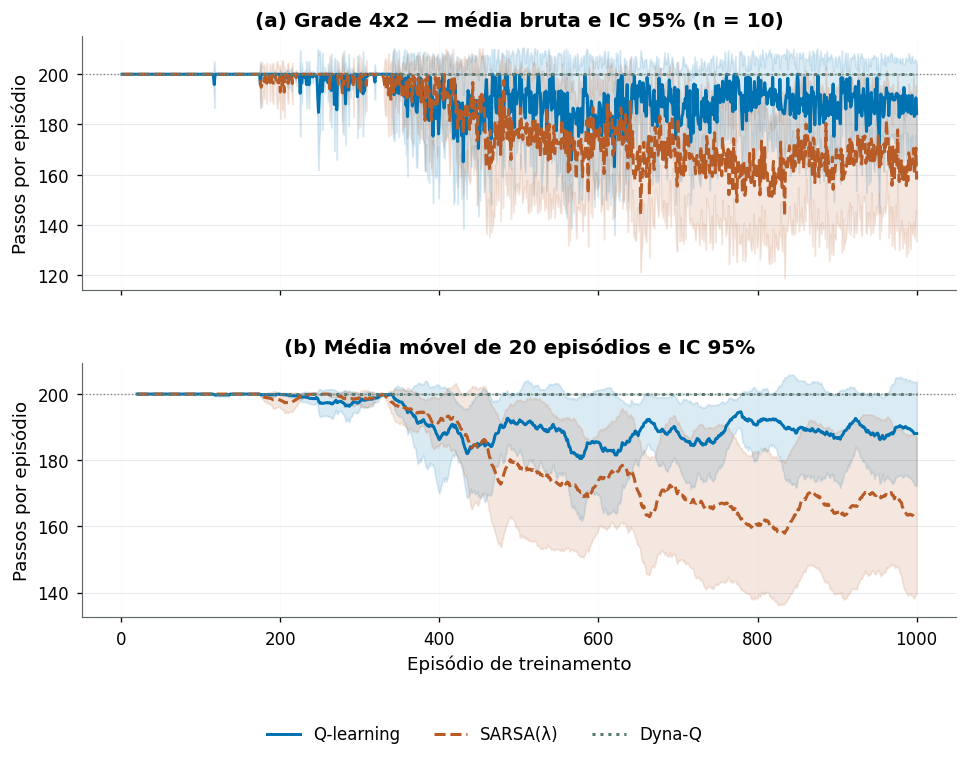

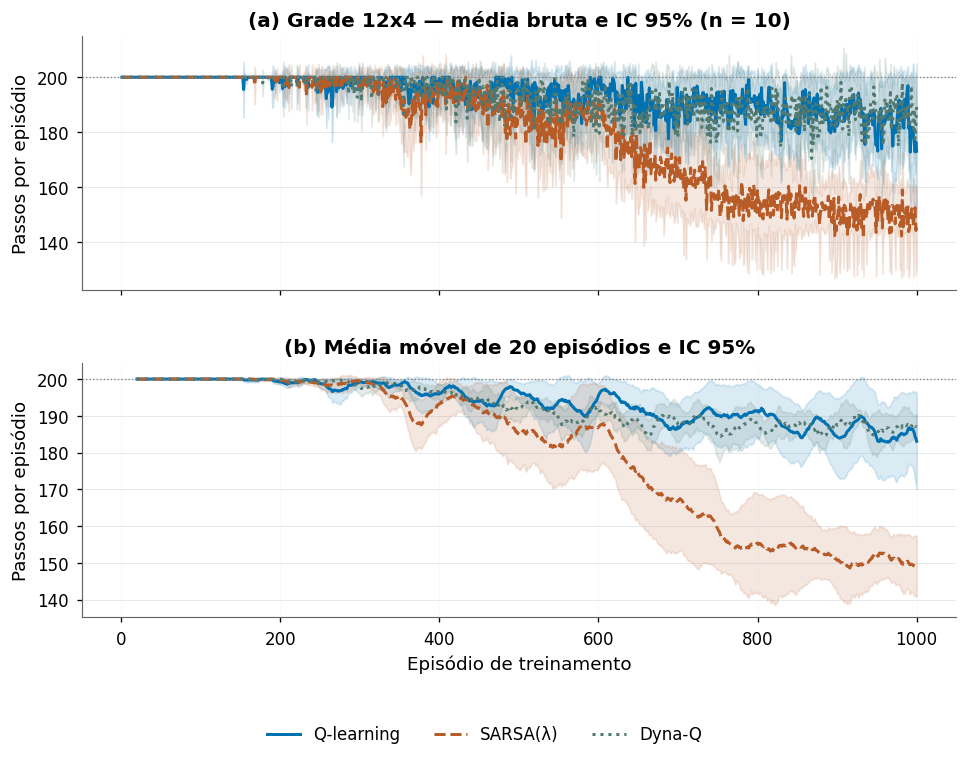

In [6]:
for disc in ('4x2','12x4'):
    fig,axes=plt.subplots(2,1,figsize=(8.2,6.8),sharex=True)
    for alg in LABELS:
        y=np.array([r['training_metrics']['episode_steps'] for r in group_runs(disc,alg)])
        line_ci(axes[0],np.arange(1,1001),y,alg)
        line_ci(axes[1],np.arange(20,1001),rolling(y),alg)
    for ax in axes:ax.axhline(200,color='gray',ls=':',lw=.8)
    axes[0].set(ylabel='Passos por episódio',title=f'(a) Grade {disc} — média bruta e IC 95% (n = 10)')
    axes[1].set(xlabel='Episódio de treinamento',ylabel='Passos por episódio',title='(b) Média móvel de 20 episódios e IC 95%')
    axes[0].legend(loc='lower left',ncol=3)
    save_figure(fig,f'passos_episodios_{disc}')

### 4.2. Retorno e sucesso por interações reais
O desempenho do treino inclui exploração; ele não substitui avaliação greedy. O eixo horizontal conta somente chamadas reais a `env.step`, excluindo planejamento. O suporte comum evita comparar métodos em regiões sem observações de todas as seeds.

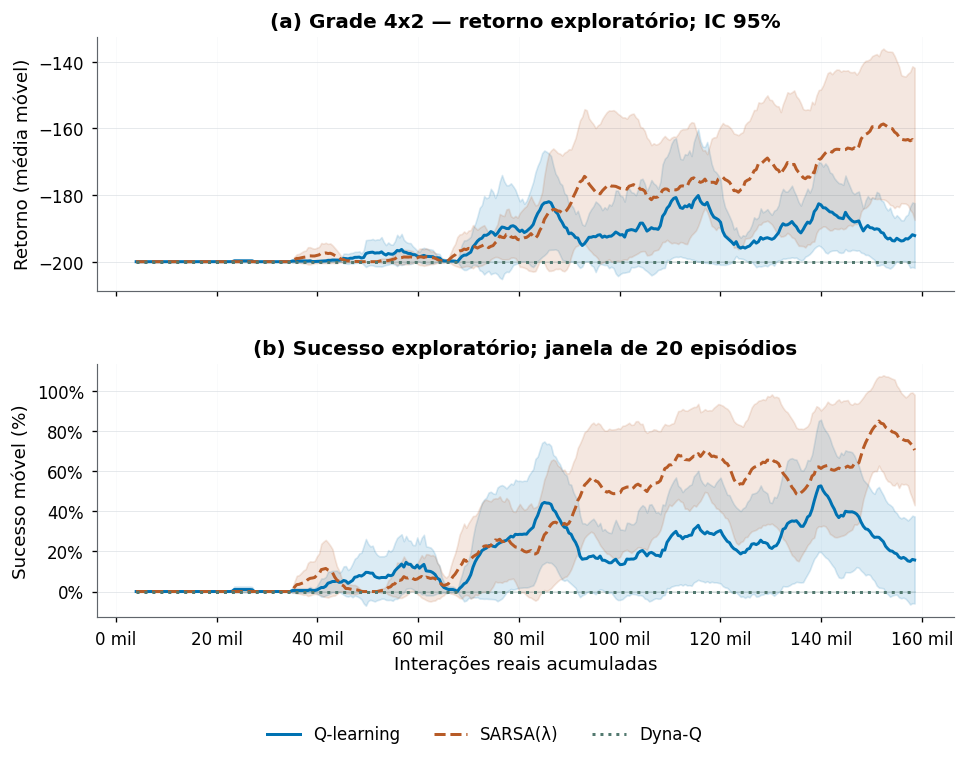

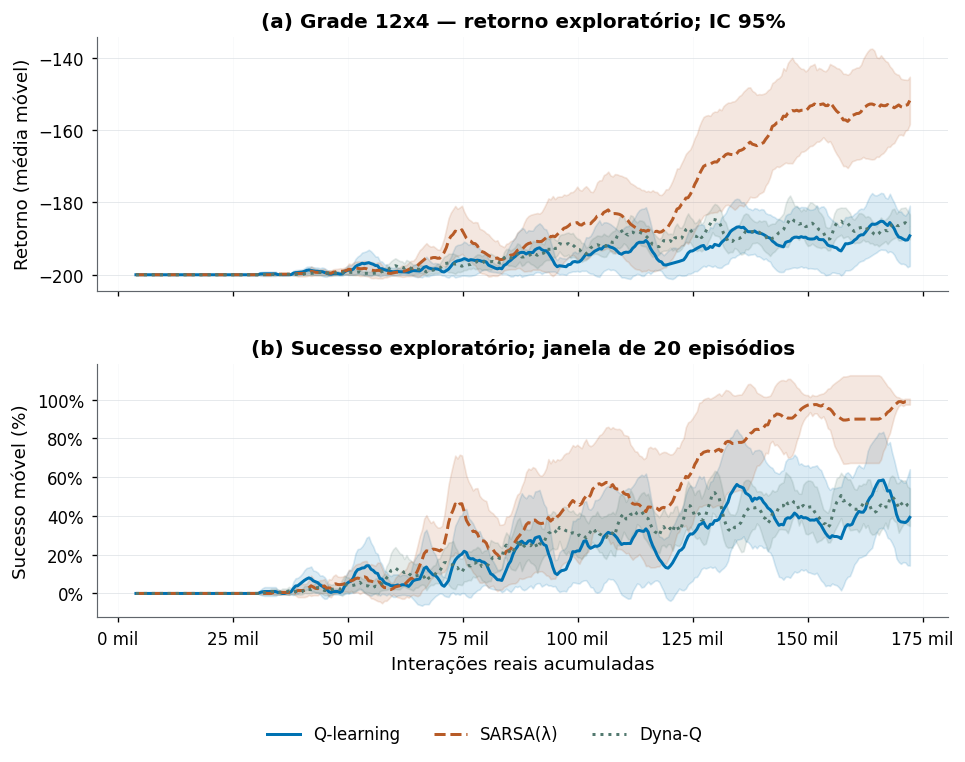

In [7]:
for disc in ('4x2','12x4'):
    allrr=[r for alg in LABELS for r in group_runs(disc,alg)]
    start=max(r['training_metrics']['cumulative_env_steps'][19] for r in allrr)
    stop=min(r['training_metrics']['cumulative_env_steps'][-1] for r in allrr)
    grid=np.linspace(start,stop,350)
    fig,axes=plt.subplots(2,1,figsize=(8.2,6.8),sharex=True)
    for alg in LABELS:
        rr=group_runs(disc,alg)
        for ax,field in zip(axes,('episode_returns','episode_successes')):
            smoothed=rolling([r['training_metrics'][field] for r in rr])
            yy=[np.interp(grid,r['training_metrics']['cumulative_env_steps'][19:],row) for r,row in zip(rr,smoothed)]
            line_ci(ax,grid,yy,alg)
    axes[0].set(ylabel='Retorno (média móvel)',title=f'(a) Grade {disc} — retorno exploratório; IC 95%')
    axes[1].set(xlabel='Interações reais acumuladas',ylabel='Sucesso móvel (%)',title='(b) Sucesso exploratório; janela de 20 episódios')
    from matplotlib.ticker import PercentFormatter, FuncFormatter
    axes[1].yaxis.set_major_formatter(PercentFormatter(1))
    axes[1].xaxis.set_major_formatter(FuncFormatter(lambda x,pos:f'{x/1000:.0f} mil'))
    axes[0].legend(ncol=3,loc='upper left')
    save_figure(fig,f'interacoes_{disc}')

### 4.3. Atualizações Q por episódio, com unidades explícitas

Os painéis separam (a) erros TD reais; (b) backups escalares de Q-learning e Dyna-Q, incluindo planejamento; (c) componentes com traço não nulo no SARSA(λ). Cada painel mostra contagem **no episódio** e **acumulada**, média e IC t 95%. Eixos verticais têm escalas próprias: não se comparam alturas entre unidades.

Em Dyna-Q, cada passo real gera $1+N=6$ backups escalares. Em SARSA, um erro TD modifica várias coordenadas. O código faz `q += alpha * delta * traces` em um vetor denso; contar componentes não nulos **não mede** todas as operações aritméticas e de memória. Logo `total_q_updates` não é uma unidade universal de custo.

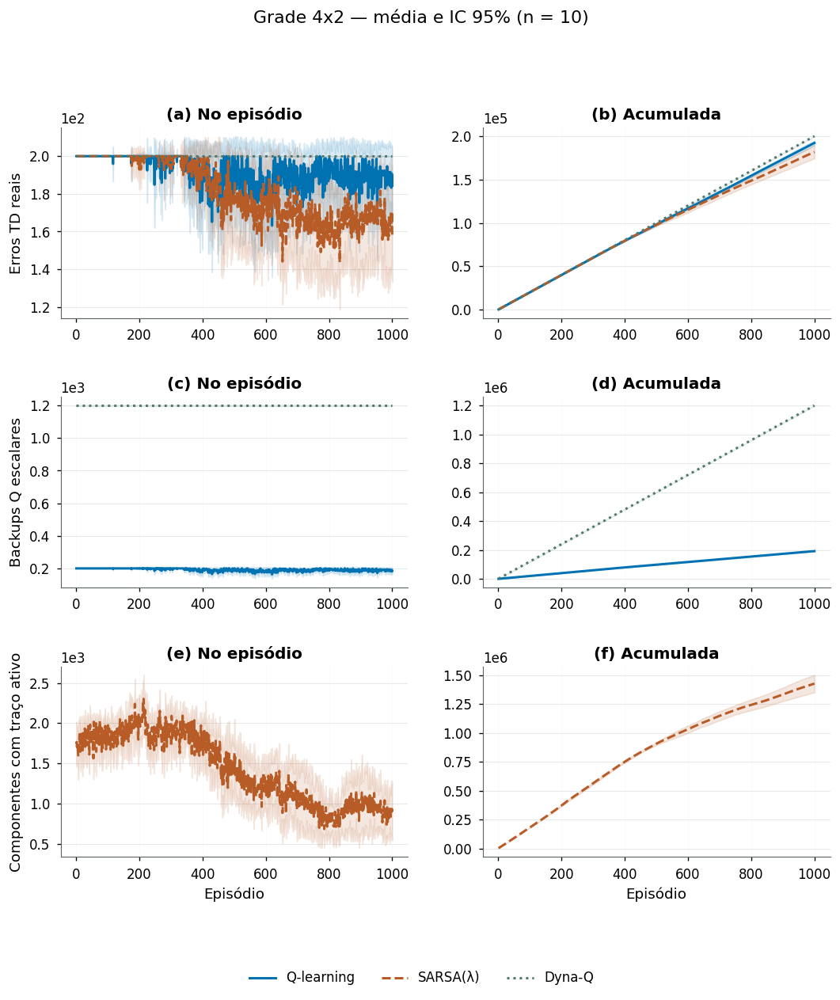

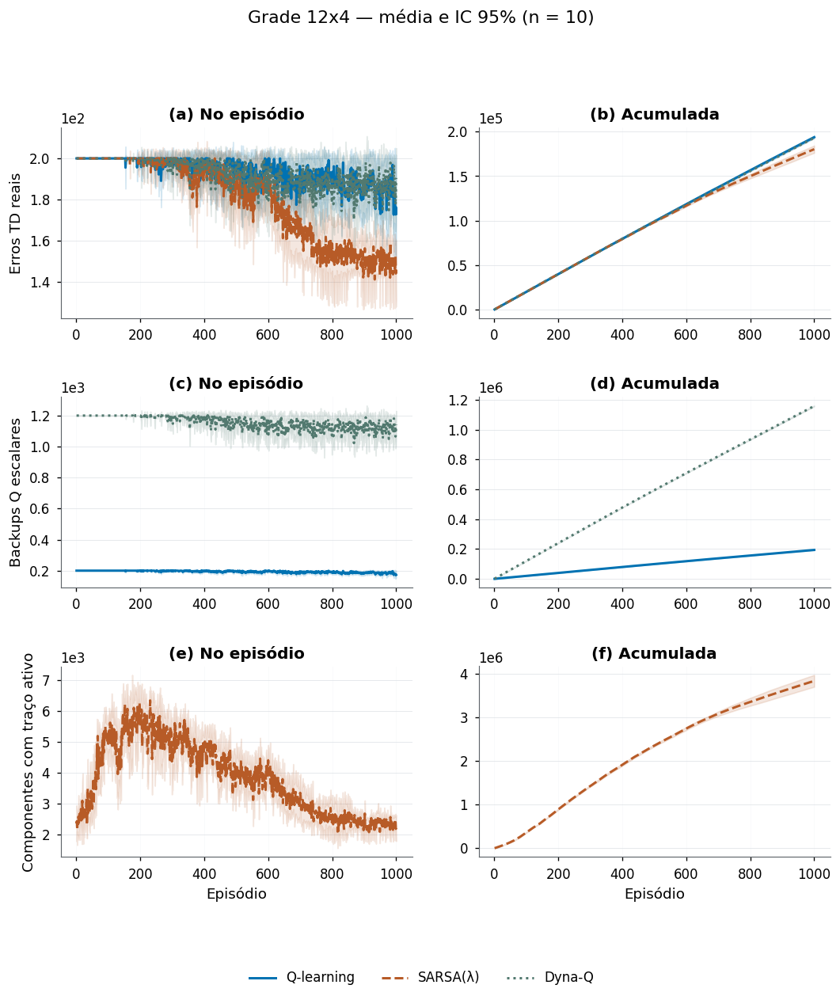

In [8]:
cost_specs=[('cumulative_real_td_updates',list(LABELS),'Erros TD reais'),
            ('cumulative_q_updates',['q_learning','dyna_q'],'Backups Q escalares'),
            ('cumulative_trace_components',['sarsa_lambda'],'Componentes com traço ativo')]
for disc in ('4x2','12x4'):
    fig,axes=plt.subplots(3,2,figsize=(9,10.5))
    for row,(field,algs,label) in enumerate(cost_specs):
        for alg in algs:
            y=np.array([r['training_metrics'][field] for r in group_runs(disc,alg)])
            per_episode=np.diff(y,axis=1,prepend=np.zeros((len(y),1)))
            line_ci(axes[row,0],np.arange(1,1001),per_episode,alg)
            line_ci(axes[row,1],np.arange(1,1001),y,alg)
        axes[row,0].set(ylabel=label,title=f'({chr(97+row*2)}) No episódio')
        axes[row,1].set(title=f'({chr(98+row*2)}) Acumulada')
        for ax in axes[row]:ax.legend(fontsize=9);ax.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
    for ax in axes[-1]:ax.set_xlabel('Episódio')
    fig.suptitle(f'Grade {disc} — média e IC 95% (n = 10)',y=1.01)
    save_figure(fig,f'atualizacoes_q_{disc}')
# Invariantes da instrumentação preservada.
for r in runs:
    t=r['training_metrics']; alg=r['config']['algorithm']
    if alg=='dyna_q':
        assert np.array_equal(np.array(t['cumulative_env_steps'])*5,t['cumulative_planning_updates'])
        assert np.array_equal(np.array(t['cumulative_env_steps'])*6,t['cumulative_q_updates'])
    elif alg=='q_learning':assert t['cumulative_env_steps']==t['cumulative_q_updates']
    else:assert t['cumulative_trace_components']==t['cumulative_q_updates']

### 4.4. Duração estritamente condicional ao sucesso
Para esta métrica, cada política contribui com sua duração média apenas se teve sucesso. Políticas sem sucesso são ausentes. O quadro seguinte evita interpretar 200 passos de fracasso como “passos até o sucesso”. O IC continua entre políticas, com n variável.

In [9]:
duration_rows=[]
for disc in ('4x2','12x4'):
    for alg in LABELS:
        rr=group_runs(disc,alg)
        v=[r['evaluation_metrics']['mean_steps_success'] for r in rr if r['evaluation_metrics']['mean_steps_success'] is not None]
        m,lo,hi=ci95(v) if len(v)>1 else (np.nan,np.nan,np.nan)
        duration_rows.append({'Grade':disc,'Método':LABELS[alg],'Políticas com sucesso / 10':len(v),
                              'Passos com falhas':np.mean([r['evaluation_metrics']['mean_steps_all'] for r in rr]),
                              'Passos condicionais':m,'IC inferior':lo,'IC superior':hi})
duration_table=pd.DataFrame(duration_rows)
display(duration_table.round(2));duration_table.to_csv(OUT/'duracao_avaliacao.csv',index=False)

,Grade,Método,Políticas com sucesso / 10,Passos com falhas,Passos condicionais,IC inferior,IC superior
0,4x2,Q-learning,4,184.15,158.56,122.46,194.66
1,4x2,SARSA(λ),9,161.77,153.19,126.97,179.41
2,4x2,Dyna-Q,0,200.00,NaN,NaN,NaN
3,12x4,Q-learning,8,167.06,156.21,136.62,175.81
4,12x4,SARSA(λ),10,148.23,148.23,140.16,156.30
5,12x4,Dyna-Q,6,190.01,169.64,153.94,185.35


## 5. Eficiência amostral e computacional

**Eficiência amostral:** SARSA(λ) apresentou a melhor combinação observada de AUC de treino, sucesso final e número total de interações nas duas grades. O orçamento fixou episódios, não um número idêntico de transições; atingir o objetivo cedo reduz o consumo de interações. Não há avaliações greedy intermediárias em orçamentos iguais de transições, portanto não se estima uma curva de generalização greedy ao longo do treino.

**Eficiência computacional:** Q-learning tem menos trabalho de atualização por passo; Dyna-Q paga pelo modelo e cinco backups adicionais. Nos tempos medidos, SARSA foi mais rápido na grade 4×2, enquanto Q-learning e SARSA ficaram próximos em 12×4. Não há vencedor universal: comparar sucesso e tempo conjuntamente. Contagens de traços não equivalem a backups escalares ou FLOPs.

A soma dos tempos individuais foi 3.492,42 s; com dois workers ela não é o tempo decorrido da campanha. Tempos dependem de hardware, carga e implementação. A latência registrada inclui consulta Q, argmax e desempate; **exclui discretização, transição do ambiente e renderização**. Ela não mede todo o ciclo de controle.

Totais preservados: {'cumulative_env_steps': 11411906, 'cumulative_planning_updates': 19654480, 'cumulative_trace_components': 52575778}


,Grade,Método,Interações reais,Planejamento,Componentes traços,Treino (s),Seleção ação (µs)
0,4x2,Q-learning,192198.6,0.0,0.0,25.472,49.212
1,4x2,SARSA(λ),181792.1,0.0,1427373.8,23.759,48.542
2,4x2,Dyna-Q,200000.0,1000000.0,0.0,119.653,47.830
3,12x4,Q-learning,193814.7,0.0,0.0,27.110,52.210
4,12x4,SARSA(λ),180295.6,0.0,3830204.0,27.206,56.417
5,12x4,Dyna-Q,193089.6,965448.0,0.0,126.042,51.659


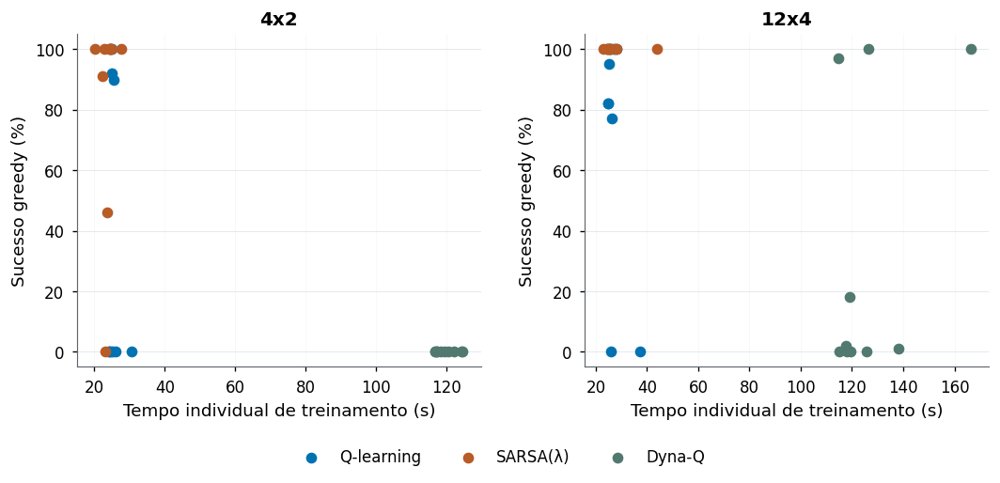

In [10]:
cost_rows=[]
for disc in ('4x2','12x4'):
    for alg in LABELS:
        rr=group_runs(disc,alg)
        cost_rows.append({'Grade':disc,'Método':LABELS[alg],
          'Interações reais':np.mean([r['training_metrics']['cumulative_env_steps'][-1] for r in rr]),
          'Planejamento':np.mean([r['training_metrics']['cumulative_planning_updates'][-1] for r in rr]),
          'Componentes traços':np.mean([r['training_metrics']['cumulative_trace_components'][-1] for r in rr]),
          'Treino (s)':np.mean([r['training_metrics']['training_time_seconds'] for r in rr]),
          'Seleção ação (µs)':np.mean([r['evaluation_metrics']['inference_mean_ns']/1000 for r in rr])})
cost_table=pd.DataFrame(cost_rows);display(cost_table.round(3));cost_table.to_csv(OUT/'custos.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(9,4.6))
for ax,disc in zip(axes,('4x2','12x4')):
    for alg in LABELS:
        rr=group_runs(disc,alg)
        ax.scatter([r['training_metrics']['training_time_seconds'] for r in rr],
                   [r['evaluation_metrics']['success_rate']*100 for r in rr],label=LABELS[alg],color=COLORS[alg])
    ax.set(xlabel='Tempo individual de treinamento (s)',ylabel='Sucesso greedy (%)',title=disc);ax.grid(alpha=.2)
axes[0].legend(fontsize=9);save_figure(fig,'tempo_qualidade')
totals={k:sum(r['training_metrics'][k][-1] for r in runs) for k in
        ['cumulative_env_steps','cumulative_planning_updates','cumulative_trace_components']}
assert totals=={'cumulative_env_steps':11411906,'cumulative_planning_updates':19654480,'cumulative_trace_components':52575778}
print('Totais preservados:',totals)

### 5.1. Distribuição entre seeds e percentis descritivos
A unidade de análise é a política treinada: **dez observações por algoritmo/grade**, cada uma avaliada em 100 resets comuns. Calculamos P10, P25, P50, P75 e P90 com interpolação linear (`numpy.quantile`, método `linear`, tipo 7). Para valores ordenados, o índice é $h=(n-1)p$; interpolam-se os vizinhos de $h$. O intervalo interquartil é $IQR=P75-P25$. Percentis descrevem dispersão; **não são intervalos de confiança**. Com apenas dez seeds, P10/P90 são exploratórios e não estimam com precisão as caudas. Não calculamos P99 entre seeds.

A figura usa pontos para todas as seeds, caixa de P25 a P75 e traço central na mediana. Bigodes são mínimo/máximo, sem exclusão de pontos. O P95 de latência já gravado é um percentil das chamadas de seleção de ação de cada política; a mediana desses P95s **não equivale ao P95 global** nem mede todo o ciclo de controle. Tempos dependem da máquina e da carga. A análise é descritiva; não adiciona testes escolhidos após olhar os resultados.

**Leitura dos percentis:** em 4×2, Q-learning tem mediana de 0% e P75 de 91,5%, evidenciando forte heterogeneidade que a média de 38,2% resume mal. Em 12×4, Dyna-Q tem mediana de 1,5% apesar da média de 31,8%; poucas políticas de alto sucesso elevam a média. SARSA(λ) apresenta P25=P50=P75=100% na grade 12×4, um fato da amostra observada, sem garantia populacional.

Percentis de 60 políticas, sem retreino; pontos representam seeds, não episódios.


,Grade,Método,Métrica,n,Mínimo,P10,P25,P50,P75,P90,Máximo,IQR
0,4x2,Q-learning,Sucesso greedy (%),10,0.000,0.000,0.000,0.000,91.500,100.000,100.000,91.500
1,4x2,Q-learning,Tempo de treino (s),10,24.107,24.275,24.512,24.924,25.396,26.459,30.635,0.884
2,4x2,Q-learning,Interações reais,10,187475.000,187753.100,189082.500,192450.000,195204.250,196072.600,197320.000,6121.750
3,4x2,Q-learning,Passos médios na avaliação,10,130.040,158.444,169.665,200.000,200.000,200.000,200.000,30.335
4,4x2,Q-learning,P95 seleção de ação (µs),10,77.000,77.990,79.150,80.650,83.800,84.600,86.400,4.650
5,4x2,SARSA(λ),Sucesso greedy (%),10,0.000,41.400,93.250,100.000,100.000,100.000,100.000,6.750
6,4x2,SARSA(λ),Tempo de treino (s),10,20.234,22.089,22.977,23.872,24.565,25.046,27.565,1.588
7,4x2,SARSA(λ),Interações reais,10,158586.000,171792.600,177073.750,184487.500,189596.000,191314.500,192246.000,12522.250
8,4x2,SARSA(λ),Passos médios na avaliação,10,119.350,119.350,124.202,179.075,189.180,193.160,200.000,64.978
9,4x2,SARSA(λ),P95 seleção de ação (µs),10,70.500,74.460,77.875,81.900,82.500,83.860,84.400,4.625


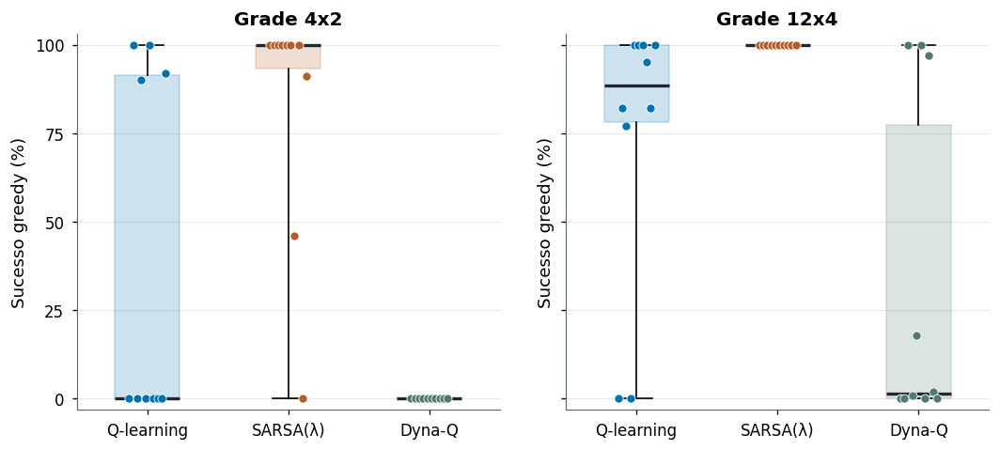

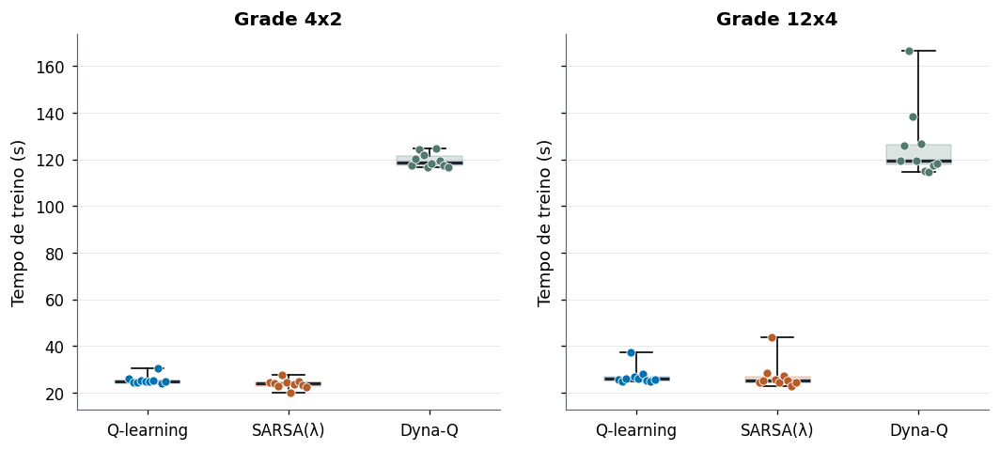

In [11]:
quantile_rows=[]
extractors={
 'Sucesso greedy (%)':lambda r:100*r['evaluation_metrics']['success_rate'],
 'Tempo de treino (s)':lambda r:r['training_metrics']['training_time_seconds'],
 'Interações reais':lambda r:r['training_metrics']['cumulative_env_steps'][-1],
 'Passos médios na avaliação':lambda r:r['evaluation_metrics']['mean_steps_all'],
 'P95 seleção de ação (µs)':lambda r:r['evaluation_metrics']['inference_p95_ns']/1000}
for disc in ('4x2','12x4'):
    for alg in LABELS:
        rr=group_runs(disc,alg)
        for metric,extract in extractors.items():
            values=np.array([extract(r) for r in rr],dtype=float)
            assert len(values)==10 and np.isfinite(values).all()
            q=np.quantile(values,[.10,.25,.50,.75,.90],method='linear')
            assert np.all(np.diff(q)>=0)
            quantile_rows.append({'Grade':disc,'Método':LABELS[alg],'Métrica':metric,'n':10,
                'Mínimo':values.min(),'P10':q[0],'P25':q[1],'P50':q[2],'P75':q[3],'P90':q[4],
                'Máximo':values.max(),'IQR':q[3]-q[1]})
quantiles=pd.DataFrame(quantile_rows)
quantiles.to_csv(OUT/'percentis_entre_seeds.csv',index=False)
display(quantiles.round(3))
for metric,name in [('Sucesso greedy (%)','distribuicao_sucesso'),('Tempo de treino (s)','distribuicao_tempo')]:
    fig,axes=plt.subplots(1,2,figsize=(9,4.8),sharey=True)
    for ax,disc in zip(axes,('4x2','12x4')):
        values=[np.array([extractors[metric](r) for r in group_runs(disc,alg)]) for alg in LABELS]
        boxes=ax.boxplot(values,positions=[1,2,3],widths=.46,patch_artist=True,
             whis=(0,100),showfliers=False,medianprops={'color':'#20262D','linewidth':2})
        for i,(alg,vals,patch) in enumerate(zip(LABELS,values,boxes['boxes']),1):
            patch.set_facecolor(COLORS[alg]);patch.set_alpha(.20);patch.set_edgecolor(COLORS[alg])
            ax.scatter(i+np.linspace(-.13,.13,len(vals)),vals,s=30,color=COLORS[alg],edgecolors='white',linewidths=.5,zorder=4)
        ax.set_xticks([1,2,3],list(LABELS.values()));ax.set(title=f'Grade {disc}',ylabel=metric)
        if 'Sucesso' in metric:ax.set_ylim(-3,103);ax.set_yticks([0,25,50,75,100])
    save_figure(fig,name)
print('Percentis de 60 políticas, sem retreino; pontos representam seeds, não episódios.')

### 5.2. Inferência estatística predefinida
Os testes abaixo referem-se à **AUC de treinamento**, não ao sucesso de avaliação. O pareamento usa identificadores de seeds; as trajetórias não são idênticas entre métodos. A correção Holm controla três comparações por grade, não uma família global com ambas as grades. Intervalos bootstrap já publicados: 10.000 reamostragens pareadas, seed fixa. ICs degenerados de sucesso em 0% ou 100% descrevem a amostra e não garantem o mesmo resultado em futuras seeds.

In [12]:
inference=json.loads(read_asset('relatorios/final_v2/inferencia_auc.json'))
for disc,detail in inference['by_discretization'].items():
    display(Markdown(f"**Grade {disc}:** Friedman = {detail['friedman']['statistic']:.3f}; p = {detail['friedman']['p_value']:.7f}"))
    infer_rows=[]
    for item in detail['post_hoc']:
        infer_rows.append({'Comparação':LABELS[item['left']]+' − '+LABELS[item['right']],
            'Diferença AUC':item['mean_difference_left_minus_right'],'p Holm':item['p_holm'],
            'Efeito rank-biserial':item['rank_biserial_left_minus_right'],
            'IC inferior':item['bootstrap_ci95_low'],'IC superior':item['bootstrap_ci95_high']})
    display(pd.DataFrame(infer_rows).round(6))

**Grade 12x4:** Friedman = 15.200; p = 0.0005005

,Comparação,Diferença AUC,p Holm,Efeito rank-biserial,IC inferior,IC superior
0,Q-learning − SARSA(λ),-0.067595,0.005859,-1.000000,-0.084570,-0.048874
1,Q-learning − Dyna-Q,-0.003673,0.275391,-0.418182,-0.009965,0.001862
2,SARSA(λ) − Dyna-Q,0.063922,0.005859,1.000000,0.046281,0.080169


**Grade 4x2:** Friedman = 16.800; p = 0.0002249

,Comparação,Diferença AUC,p Holm,Efeito rank-biserial,IC inferior,IC superior
0,Q-learning − SARSA(λ),-0.052019,0.009766,-0.890909,-0.088372,-0.021882
1,Q-learning − Dyna-Q,0.039007,0.005859,1.000000,0.028582,0.049435
2,SARSA(λ) − Dyna-Q,0.091026,0.005859,1.000000,0.063334,0.123815


## 6. State aliasing: Dyna-Q versus SARSA(λ)

**Fato:** a grade 4×2 agrega estados físicos distintos. Dyna-Q obteve 0% de sucesso de avaliação nessa grade, contra 31,8% em 12×4; SARSA obteve 83,7% e 100%. **Interpretação:** a representação mais fina distingue situações relevantes de posição e velocidade, mas a mudança também altera cobertura, tamanho da tabela e dinâmica da aprendizagem.

No Dyna-Q, o modelo aprende a distribuição de desfechos condicionada à célula agregada e à distribuição de visitas. A mesma ação pode gerar futuros distintos dentro de uma célula. Quando a política muda, também pode mudar a mistura de estados físicos visitados. Repetir cinco vezes esse modelo pode propagar erro de agregação. Guardar contagens de múltiplos desfechos melhora a descrição empírica, mas não recupera a informação física perdida.

No SARSA(λ), os traços propagam crédito ao longo da trajetória realmente observada, sem simular uma sequência pelo modelo agregado. Isso pode ser vantajoso neste problema. Ainda assim, a própria função Q do SARSA sofre aliasing; traços não restauram a propriedade de Markov.

**Hipótese não demonstrada:** erro do modelo agregado explica o baixo desempenho do Dyna-Q. Para testar causalidade seriam necessárias ablações de resolução, N, representação/modelo e orçamento equivalente. Esta rodada não executa essas ablações e não atribui causalidade aos resultados.

## 7. Políticas, trajetórias e vídeos reais

As seis demonstrações usam a menor seed de treino (3100) e o reset 900000, escolhido previamente. Mostram êxitos e fracassos, sem selecionar a melhor execução. São rollouts de checkpoints reais preservados, não animações ilustrativas. Os vídeos já estão incorporados e não geram novas interações. A taxa de sucesso deve ser lida na avaliação de 100 episódios por política, nunca inferida de um único vídeo.

### Grade 4x2 — seed 3100 / reset 900000

**Q-learning**

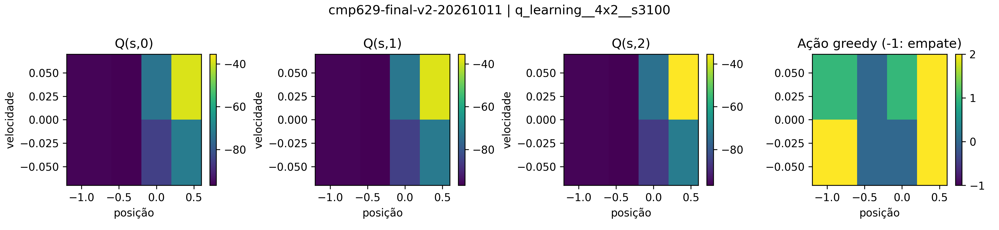

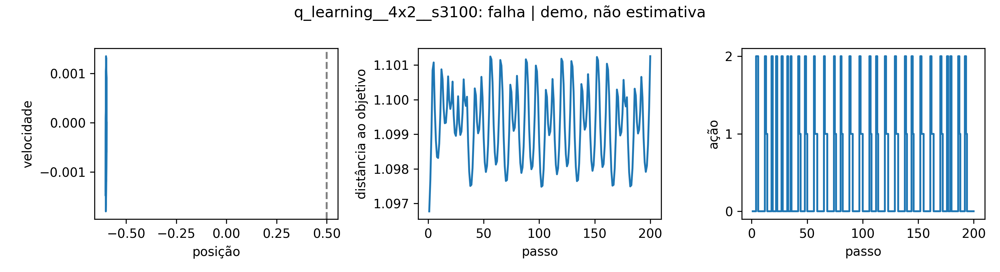

**SARSA(λ)**

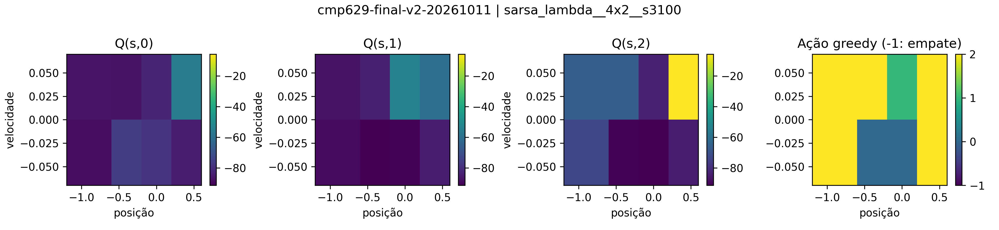

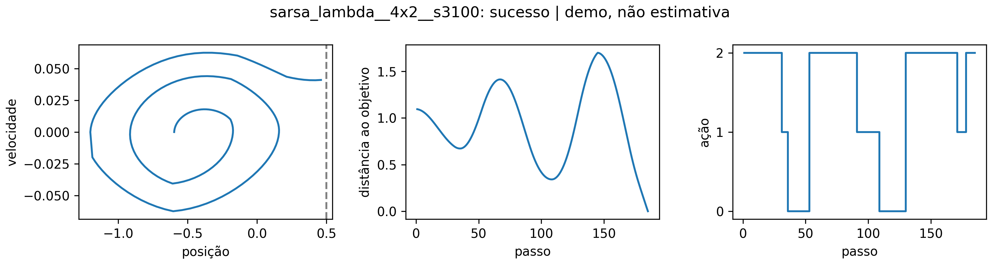

**Dyna-Q**

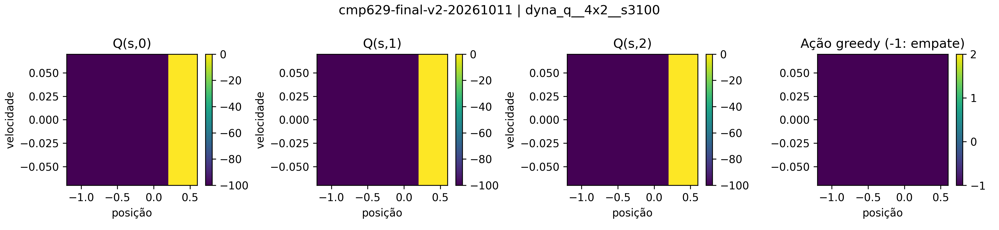

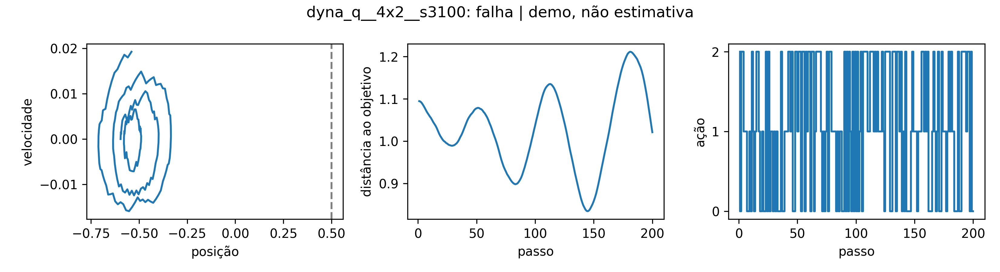

### Grade 12x4 — seed 3100 / reset 900000

**Q-learning**

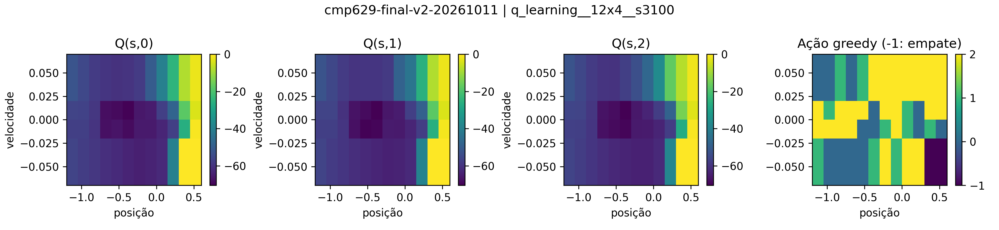

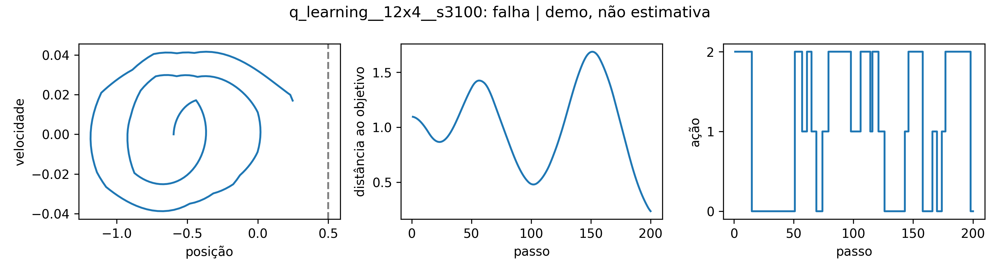

**SARSA(λ)**

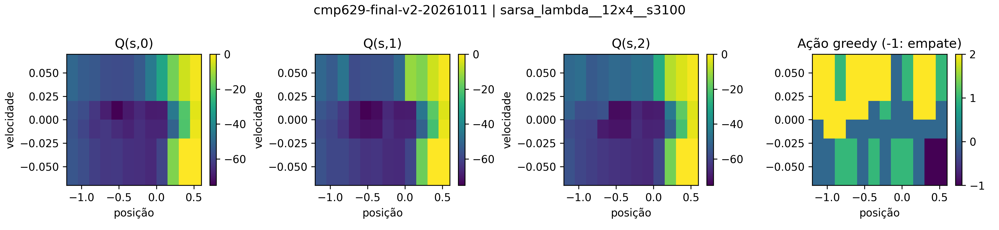

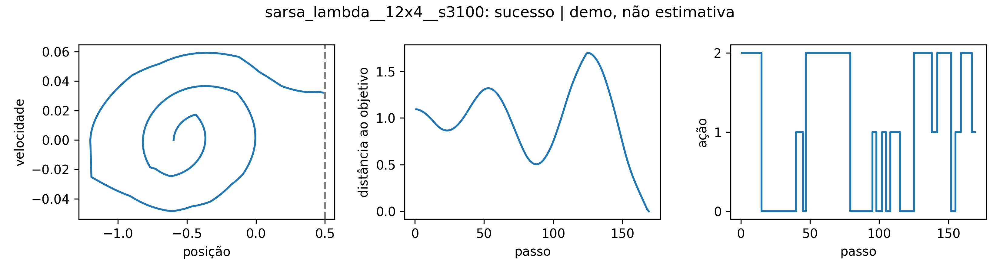

**Dyna-Q**

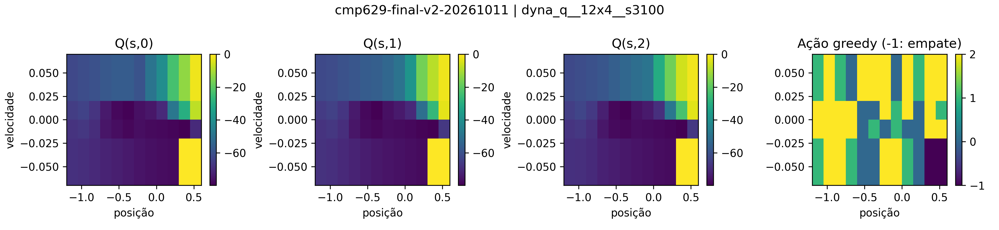

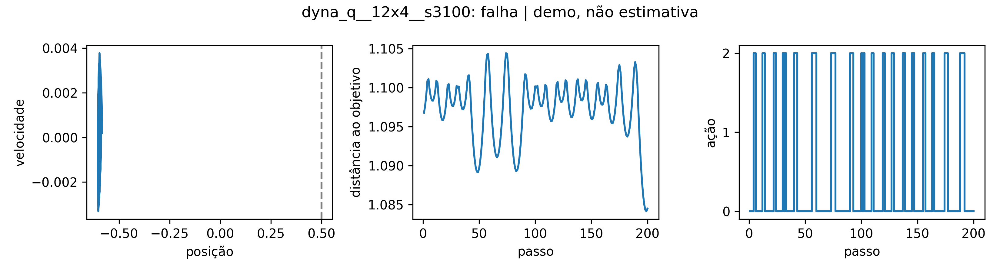

In [13]:
for disc in ('4x2','12x4'):
    display(Markdown(f'### Grade {disc} — seed 3100 / reset 900000'))
    for alg in LABELS:
        name=f'{alg}__{disc}__s3100'
        display(Markdown(f'**{LABELS[alg]}**'))
        for kind in ('policy','trajectory'):
            display(Image(read_asset(f'figuras/animacoes_final_v2/{name}.{kind}.png'),width=950))
    video_path=OUT/f'comparacao_{disc}.mp4'
    video_path.write_bytes(read_asset(f'figuras/animacoes_final_v2/comparacao_{disc}.mp4'))
    display(Video(str(video_path),embed=True,width=950))

## 8. Diário de bordo, tentativas inferiores e correções

Registro reconstruído a partir dos protocolos, históricos e auditorias preservados; não se inventam conversas ou cronologia pessoal.

| Etapa / fonte | Evidência ou dificuldade | Tratamento e limite |
|---|---|---|
| Triagem v1 | 108 execuções, apenas três seeds por configuração | Usada para selecionar, não para inferência final |
| Dyna-Q 4×2 | As 18 execuções exploratórias não tiveram sucesso de avaliação | Aumentar N dentro da grade testada não resolveu; causalidade do aliasing não demonstrada |
| Auditoria 11/10, `docs/AUDITORIA.md` | “stable_episode” representava primeiro atingimento; não garantia manutenção | Distinguir limiar inicial e janela final; não chamar de estabilidade sustentada |
| Auditoria de contadores | `total_q_updates` tinha unidades distintas | Separar TD real, planejamento e componentes de traços |
| Revisão da avaliação | Treino com ε não equivale à política greedy | Campanha final usa 100 resets comuns e dez seeds novas |
| Modelo Dyna | Risco de sobrescrever desfechos da célula pelo último observado | Código recebido já preserva distribuição empírica; não afirmar que o bug ocorreu no treino final |
| Entrega 13/10 | Notebook anterior concentrava apresentação de PNGs e deixava explicações no relatório externo | Código incorporado, dados portáteis e gráficos gerados a partir dos históricos |

### 8.1. Configurações que tiveram desempenho inferior
A tabela gerada abaixo mostra, por método, a melhor e a pior AUC média global entre as seis configurações da triagem. A ordenação é exploratória (seis execuções por configuração: duas grades × três seeds). Mudanças conjuntas de α, λ, decay e N não identificam efeitos individuais. Uma configuração “pior” nesta amostra não é universalmente ruim.

Mecanismos plausíveis: α elevado com traços acumulativos pode ampliar correções; exploração que cai depressa pode reduzir cobertura; N alto aumenta custo e pode reiterar um modelo agregado inadequado. Essas são explicações a investigar, não causas comprovadas pela triagem.

In [14]:
triage_rows=[]
for r in triage:
    c=r['config']; hp=c['hyperparameters'];ret=np.array(r['training_metrics']['episode_returns'])
    auc=np.trapezoid((ret+200)/200)/(len(ret)-1) if hasattr(np,'trapezoid') else np.trapz((ret+200)/200)/(len(ret)-1)
    triage_rows.append({'algorithm':c['algorithm'],'grade':c['discretization']['name'],'seed':c['seed'],
                       **hp,'AUC':auc,'sucesso':r['evaluation_metrics']['success_rate']})
triage_df=pd.DataFrame(triage_rows)
hp_table=triage_df.groupby(['algorithm','alpha','lambda','epsilon_decay','N'],as_index=False).agg(AUC=('AUC','mean'),n=('AUC','size'))
hp_table=hp_table.sort_values(['algorithm','AUC'],ascending=[True,False])
display(hp_table.round(6));hp_table.to_csv(OUT/'triagem_18_configuracoes.csv',index=False)
worst_best=pd.concat([g.iloc[[0,-1]].assign(posicao=['melhor','pior']) for _,g in hp_table.groupby('algorithm')])
display(worst_best.round(6))
dyna_coarse=triage_df[(triage_df.algorithm=='dyna_q')&(triage_df.grade=='4x2')]
assert len(dyna_coarse)==18 and (dyna_coarse.sucesso==0).all()

,algorithm,alpha,lambda,epsilon_decay,N,AUC,n
1,dyna_q,0.05,0.0,0.995,5,0.017548,6
2,dyna_q,0.05,0.0,0.995,10,0.015485,6
0,dyna_q,0.05,0.0,0.995,1,0.011642,6
3,dyna_q,0.10,0.0,0.995,1,0.006449,6
4,dyna_q,0.10,0.0,0.995,5,0.005423,6
5,dyna_q,0.10,0.0,0.995,10,0.004308,6
8,q_learning,0.10,0.0,0.990,0,0.046546,6
6,q_learning,0.05,0.0,0.990,0,0.033045,6
10,q_learning,0.20,0.0,0.990,0,0.028655,6
11,q_learning,0.20,0.0,0.995,0,0.027991,6


,algorithm,alpha,lambda,epsilon_decay,N,AUC,n,posicao
1,dyna_q,0.05,0.0,0.995,5,0.017548,6,melhor
5,dyna_q,0.10,0.0,0.995,10,0.004308,6,pior
8,q_learning,0.10,0.0,0.990,0,0.046546,6,melhor
9,q_learning,0.10,0.0,0.995,0,0.025098,6,pior
13,sarsa_lambda,0.02,0.9,0.995,0,0.090396,6,melhor
12,sarsa_lambda,0.02,0.7,0.995,0,0.028105,6,pior


## 9. Conclusões, limitações e relação com MPC/RL

1. **Resultado sustentado:** SARSA(λ) teve maior sucesso médio de avaliação e AUC de treino nas duas grades deste protocolo. A variabilidade de Q-learning e Dyna-Q torna inadequado resumir o estudo por uma seed.
2. **Custos:** planejamento aumentou o trabalho e tempo do Dyna-Q; os traços do SARSA tiveram custo vetorizado. Atualizações de tipos diferentes não formam uma moeda computacional comum.
3. **Representação:** a resolução altera o problema aproximado; aliasing é explicação plausível, não isolada causalmente. Duas grades e um ambiente não sustentam generalização universal.
4. **Validade:** dez seeds, distribuição estreita de resets, hiperparâmetros globais, treino exploratório e avaliação apenas ao final; IC t aproximado; medições de tempo sob carga; tempo não incluído no estado.
5. **MPC/RL:** a contribuição é metodológica: separar treinamento, planejamento e seleção de ação, registrar unidades e exigir qualidade comparável. Não houve MPC, QP ou KKT neste experimento. A dimensão física do estado permaneceu dois; aumentar a grade não é aumentar n_x. Nada aqui demonstra relações causais com N do horizonte MPC, dim(H), dim(KKT), ρ(A) ou norma de A. O N do Dyna-Q é número de backups, conceito distinto do horizonte MPC.

### 9.1. Referências e rastreabilidade
- Enunciado oficial, *Mini-Projeto: Modelagem e solução de problemas com Aprendizado por Reforço*, pp. 1–4; seções 3, 4.1–4.3 e 5.
- Relatório fornecido `CMP629_MiniProjeto_MountainCar_Padrao_Oficial(3).pdf`, 20 páginas: ponto de partida científico e visual.
- Sutton, R. S.; Barto, A. G. *Reinforcement Learning: An Introduction*, 2ª ed., 2018: capítulos 6 (TD), 8 (planejamento/Dyna) e 12 (traços). Arquivo `BartoSutton.pdf` fornecido.
- Gymnasium 1.2.1, implementação `gymnasium/envs/classic_control/mountain_car.py` e `TimeLimit`, versão registrada pelo projeto.
- Repositório: https://github.com/antoniomoraes85/reinforcement-learning-projects/tree/19dcf17bfa589bb3cb16da4bd9f1862c501fddbd/mountaincar-tabular
- `configs/protocolo_final_v2.json`, `docs/METODOLOGIA_FINAL.md`, `relatorios/final_v2/RELATORIO_TECNICO.md`, históricos gzip e bundles originais: fontes de configuração e resultados.

### 9.2. Cobertura da rubrica
Discretização (15%): seção 1 e verificação de cortes; agentes (25%): seção 2, código incorporado; rigor (10%): seção 3 e históricos preservados; gráficos (15%): seção 4; discussão (20%): seções 5–6 e 9; diário (15%): seção 8.

O enunciado valoriza compreensão e análise do estudante. Os integrantes devem revisar as interpretações e estar aptos a explicar as decisões metodológicas. Esta compilação declara o uso de assistência de IA na organização, implementação gráfica e revisão; não demonstra domínio individual por si só.

### 9.3. Reprodução e estado de validação
Históricos, código, vídeos, gráficos e outputs acompanham o pacote. A execução das células é registrada em VALIDACAO_EXECUCAO.json; não há treinamento. O Colab hospedado não foi testado; consulte `STATUS_ENTREGA.md`.

In [15]:
validation={'final_runs':len(runs),'triage_runs':len(triage),'training_executed':False,
            'evaluation_executed':False,'embedded_payload_sha256':PAYLOAD_SHA256,
            'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
            'checks':'contagens, seeds, retornos, sucesso por política e unidades Q'}
(OUT/'validacao_dados_notebook.json').write_text(json.dumps(validation,indent=2),encoding='utf-8')
print('Análise concluída. Resultados em',OUT.resolve())

Análise concluída. Resultados em /workspace/scratch/6e0a9a68d9d5/ENTREGA_FINAL_CMP629/validacao_kernel_limpo/cmp629_reproduzido
